In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/matching/D4/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'scm.csv')
df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,1267145,0.15,0.17,100.0,0.35,2214,1264931,2634,0,cosine,[title],1024,0,1,salted_qgrams,,4
1,Matching with cosine,299517,0.25,0.74,100.0,1.47,2214,297303,2634,0,cosine,[title],1024,0,1,salted_qgrams,,4
2,Matching with cosine,630067,0.20,0.35,100.0,0.70,2214,627853,2634,0,cosine,[title],1024,0,1,salted_qgrams,,4
3,Matching with cosine,135145,0.30,1.64,100.0,3.22,2214,132931,2634,0,cosine,[title],1024,0,1,salted_qgrams,,4
4,Matching with cosine,61239,0.35,3.62,100.0,6.98,2214,59025,2634,0,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Matching with scm,5852672,0.05,0.04,100.0,0.08,2214,5850458,2634,0,scm,[title],1024,0,32,salted_qgrams,,4
2428,Matching with scm,5851574,0.25,0.04,100.0,0.08,2214,5849360,2634,0,scm,[title],1024,0,32,salted_qgrams,,4
2429,Matching with scm,5807927,0.35,0.04,100.0,0.08,2214,5805713,2634,0,scm,[title],1024,0,32,salted_qgrams,,4
2430,Matching with scm,5843081,0.30,0.04,100.0,0.08,2214,5840867,2634,0,scm,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    2432
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
14,Matching with cosine,2467,0.85,87.84,97.88,92.59,2167,300,2587,47,cosine,[title],1024,0,1,salted_qgrams,,4
609,Matching with dice,2463,0.85,87.82,97.70,92.50,2163,300,2583,51,dice,[title],1024,0,1,salted_qgrams,,4
1228,Matching with jaccard,2485,0.70,87.53,98.24,92.57,2175,310,2595,39,jaccard,[title],1024,0,1,salted_qgrams,,4
1824,Matching with scm,733471,0.95,0.30,99.91,0.60,2212,731259,2632,2,scm,[title],1024,0,1,salted_qgrams,,4
33,Matching with cosine,2469,0.85,87.85,97.97,92.63,2169,300,2589,45,cosine,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2398,Matching with scm,2372,0.95,88.70,95.03,91.76,2104,268,2524,110,scm,[title],1024,0,31,salted_qgrams,,4
592,Matching with cosine,2518,0.95,84.75,96.39,90.19,2134,384,2554,80,cosine,[title],1024,0,32,salted_qgrams,,4
1199,Matching with dice,2518,0.95,84.75,96.39,90.19,2134,384,2554,80,dice,[title],1024,0,32,salted_qgrams,,4
1812,Matching with jaccard,2350,0.95,88.72,94.17,91.37,2085,265,2505,129,jaccard,[title],1024,0,32,salted_qgrams,,4


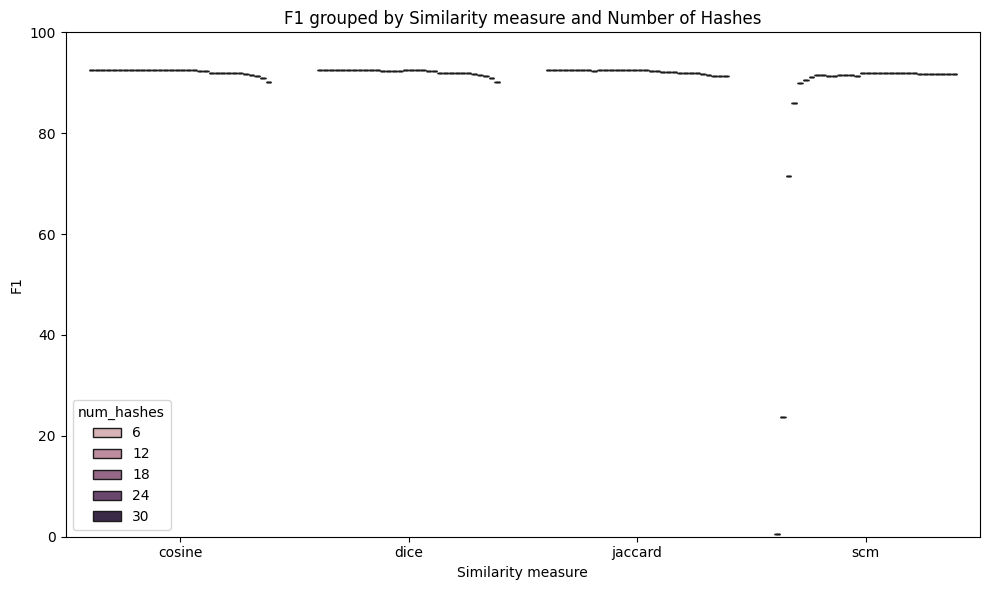

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,87.84
1,dice,1,Precision %,87.82
2,jaccard,1,Precision %,87.53
3,scm,1,Precision %,0.30
4,cosine,2,Precision %,87.85
...,...,...,...,...
379,scm,31,F1 %,91.76
380,cosine,32,F1 %,90.19
381,dice,32,F1 %,90.19
382,jaccard,32,F1 %,91.37


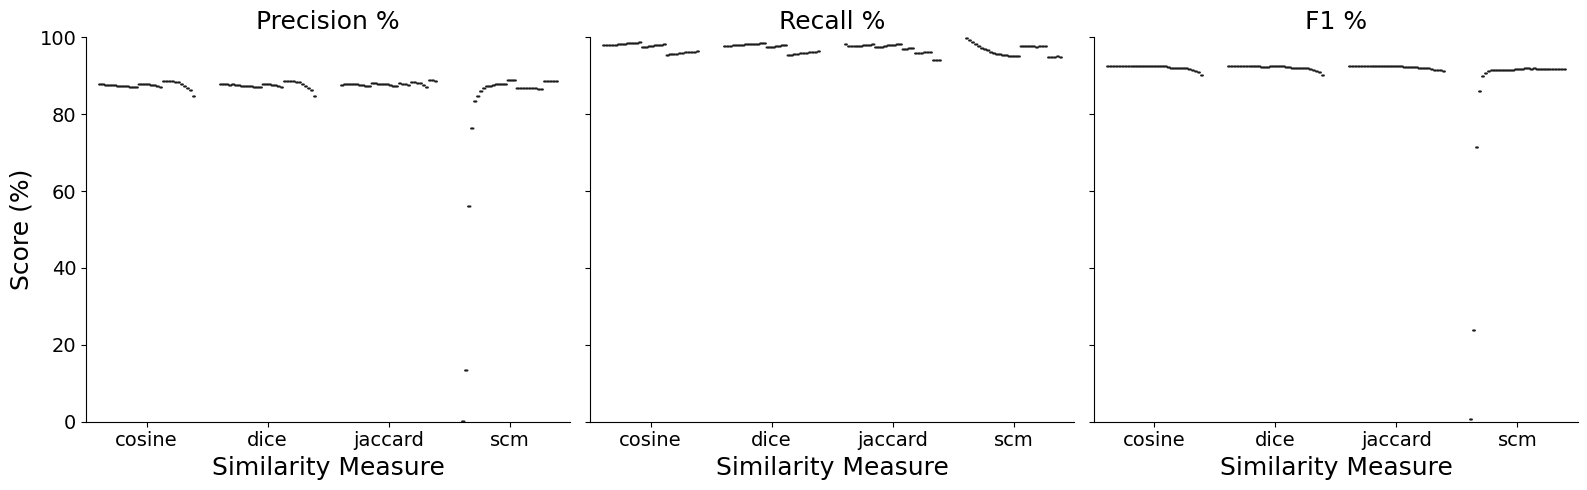

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

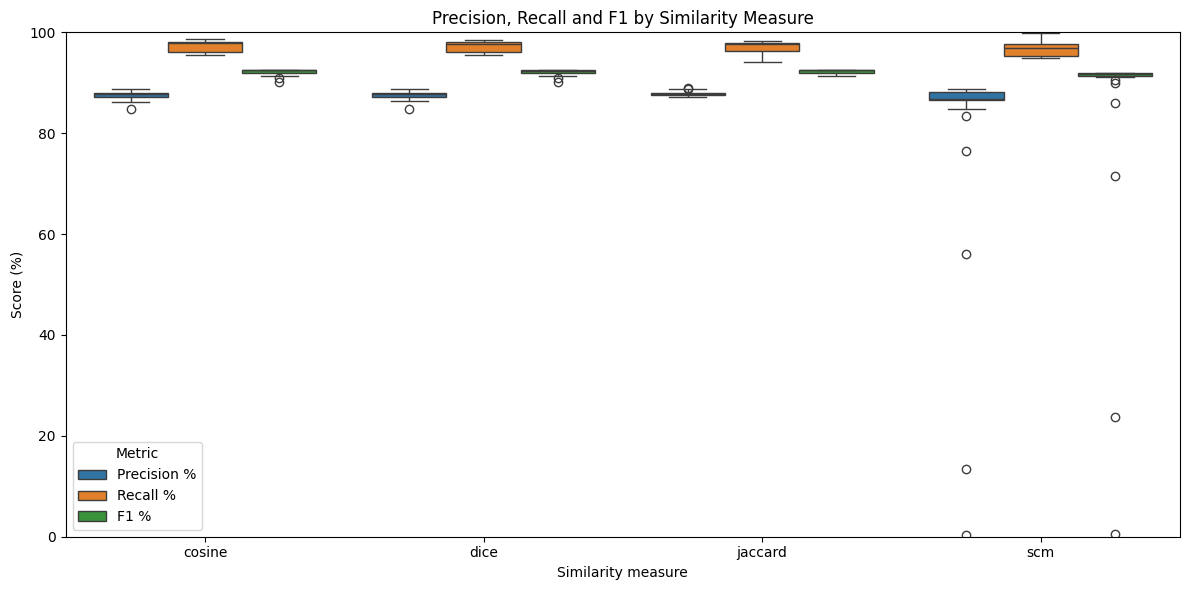

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()